In [1]:
import datetime
import matplotlib.pyplot as plt

STORE_NAME = "DMART STORE MANAGER"
MANAGER_PASSWORD = "dmart123"   # demo only
GST_PERCENT = 5                 # flat GST rate used for the demo bill
MEMBER_EXTRA_PERCENT = 2        # extra discount for DMart members
CRATE_SIZE = 10                 # suppliers deliver in crates of 10 units
LINE_WIDTH = 76
MAX_NAME_LENGTH = 22            # longest product name kept in the tables

In [3]:
codes = ["P-MILK01", "P-CURD01", "P-BRED01", "P-TOMA01", "P-BANA01",
         "P-PANR01", "P-CREM01", "P-LETT01", "N-RICE01", "N-OILS01",
         "N-DALS01", "N-DETG01", "N-SHMP01", "N-SALT01", "N-TEAS01",
         "N-BISC01", "N-SOAP01", "N-ATTA01", "N-SUGR01", "P-BUTR01"]

names = ["Milk 500ml", "Curd 400g", "Bread Loaf", "Tomatoes 1kg", "Bananas 1dz",
         "Paneer 200g", "Fresh Cream 200ml", "Lettuce 250g", "Basmati Rice 5kg",
         "Sunflower Oil 1L", "Toor Dal 1kg", "Detergent 1kg", "Shampoo 340ml",
         "Salt 1kg", "Tea 250g", "Biscuits Pack", "Soap Bar 3pk", "Atta 5kg",
         "Sugar 1kg", "Butter 100g"]

stocks = [8, 15, 40, 5, 55, 22, 3, 18, 30, 9, 60, 12, 95, 40, 6, 70, 25, 8, 50, 11]
reorder_levels = [20, 15, 10, 12, 10, 12, 10, 8, 15, 20, 15, 15, 10, 10, 12, 20, 10, 15, 12, 10]
max_levels = [60, 50, 45, 40, 40, 35, 30, 25, 100, 90, 80, 70, 60, 75, 55, 65, 60, 90, 70, 35]
daily_sales = [12, 6, 20, 8, 10, 3, 2, 6, 3, 4, 4, 2, 3, 3, 2, 5, 2, 3, 4, 2]
costs = [27, 40, 35, 28, 50, 76, 49, 33, 480, 128, 138, 98, 168, 22, 116, 26, 85, 262, 44, 52]
prices = [30, 45, 40, 35, 60, 85, 55, 40, 520, 140, 150, 110, 190, 25, 130, 30, 95, 280, 48, 58]

sales_log = []    # final amount of every bill made in this session

In [4]:
def line(char="-"):
    """Print a divider line (string repetition)."""
    print(char * LINE_WIDTH)


def header(title):
    """Print a centred title between two divider lines."""
    print()
    line("=")
    print(f"{title:^{LINE_WIDTH}}")
    line("=")


def category_from_code(code):
    """The first letter of a product code tells us the category: P or N."""
    first_letter = code[0].upper()
    if first_letter == "P":
        return "Perishable"
    elif first_letter == "N":
        return "Non-Perishable"
    else:
        return "Unknown"


# Build the categories list from the codes (a for loop over a list)
categories = []
for code in codes:
    categories.append(category_from_code(code))

print(categories)

['Perishable', 'Perishable', 'Perishable', 'Perishable', 'Perishable', 'Perishable', 'Perishable', 'Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Non-Perishable', 'Perishable']


In [5]:
def clean_name(raw_name):
    """'  mixed_fruit   JAM 500g ' -> 'Mixed Fruit Jam 500g'"""
    words = raw_name.replace("_", " ").split(" ")
    cleaned = ""
    for word in words:
        if len(word) == 0:          # an extra space gives an empty word
            continue
        fixed_word = word[0].upper() + word[1:].lower()
        if cleaned == "":
            cleaned = fixed_word
        else:
            cleaned = cleaned + " " + fixed_word
    return cleaned


def find_product(code):
    """Return the list position of a product code, or -1 if it does not exist."""
    code = code.replace(" ", "").upper()
    for i in range(len(codes)):
        if codes[i] == code:
            return i
    return -1


def read_positive_int(message):
    """Keep asking until the user types a whole number greater than 0."""
    text = input(message)
    while not text.isdigit() or int(text) <= 0:
        print("  Please enter a whole number greater than 0.")
        text = input(message)
    return int(text)


def read_positive_float(message):
    """Keep asking until the user types a number greater than 0 (decimals allowed)."""
    text = input(message)
    while not text.replace(".", "", 1).isdigit() or float(text) <= 0:
        print("  Please enter a number greater than 0.")
        text = input(message)
    return float(text)

In [6]:
def classify_stock(stock, reorder_level, max_level):
    """Level-based status of one product."""
    if stock <= reorder_level:
        return "Reorder Needed"
    elif stock >= max_level:
        return "Overstocked"
    else:
        return "Stock OK"


def days_of_cover(stock, daily_sale):
    """How many days the current stock will last. 999 means 'no sales'."""
    if daily_sale <= 0:
        return 999
    return stock / daily_sale


def restock_advice(days, category):
    """Perishables spoil, so they use much tighter limits than non-perishables."""
    if category == "Perishable":
        urgent_limit = 2
        soon_limit = 4
    else:
        urgent_limit = 7
        soon_limit = 14

    if days < urgent_limit:
        return "Reorder urgently"
    elif days <= soon_limit:
        return "Reorder soon"
    else:
        return "Stock sufficient"


def get_discount_percent(cart_total, is_member):
    """Tiered discount slabs, plus an extra offer for members on bigger carts."""
    if cart_total >= 5000:
        percent = 20
    elif cart_total >= 2000:
        percent = 10
    else:
        percent = 0

    if is_member and cart_total >= 500:     # combined condition
        percent = percent + MEMBER_EXTRA_PERCENT
    return percent


def count_statuses():
    """Return [reorder_count, ok_count, overstock_count] for all products."""
    reorder_count = 0
    ok_count = 0
    over_count = 0
    for i in range(len(codes)):
        status = classify_stock(stocks[i], reorder_levels[i], max_levels[i])
        if status == "Reorder Needed":
            reorder_count += 1
        elif status == "Stock OK":
            ok_count += 1
        else:
            over_count += 1
    return [reorder_count, ok_count, over_count]


# quick test of the rules
print(classify_stock(8, 20, 60))        # Reorder Needed
print(count_statuses())                 # [8, 9, 3]

Reorder Needed
[8, 9, 3]


In [7]:
def login():
    attempts_left = 3
    while attempts_left > 0:
        password = input(f"Enter manager password ({attempts_left} attempt(s) left): ")
        if password == MANAGER_PASSWORD:
            print("Login successful.")
            return True
        attempts_left = attempts_left - 1       # moves toward the stop condition
        print("Incorrect password.")
    print("Too many wrong attempts. Access locked.")
    return False

In [8]:
def show_inventory_report():
    header("INVENTORY STATUS REPORT")
    print(f"{'Code':<10}{'Product':<24}{'Category':<16}{'Stock':>6}   Status")
    line()

    stock_value = 0
    perishable_reorder = 0
    non_perishable_reorder = 0

    for i in range(len(codes)):
        status = classify_stock(stocks[i], reorder_levels[i], max_levels[i])
        print(f"{codes[i]:<10}{names[i]:<24}{categories[i]:<16}{stocks[i]:>6}   {status}")

        stock_value += stocks[i] * costs[i]          # running total
        if status == "Reorder Needed" and categories[i] == "Perishable":
            perishable_reorder += 1
        elif status == "Reorder Needed" and categories[i] == "Non-Perishable":
            non_perishable_reorder += 1

    counts = count_statuses()
    line()
    print(f"Products checked      : {len(codes)}")
    print(f"Reorder needed        : {counts[0]}  "
          f"(Perishable {perishable_reorder}, Non-Perishable {non_perishable_reorder})")
    print(f"Stock OK              : {counts[1]}")
    print(f"Overstocked           : {counts[2]}")
    print(f"Stock value (at cost) : Rs {stock_value:,.2f}")

In [9]:
def show_alerts():
    header("LOW-STOCK & OVERSTOCK ALERTS")
    alert_count = 0

    for i in range(len(codes)):
        status = classify_stock(stocks[i], reorder_levels[i], max_levels[i])
        if status == "Stock OK":
            continue                     # healthy product - nothing to report

        alert_count += 1
        if status == "Reorder Needed":
            # order up to the middle of the safe range
            target_level = (reorder_levels[i] + max_levels[i]) // 2
            order_qty = target_level - stocks[i]
            crates = order_qty // CRATE_SIZE
            if order_qty % CRATE_SIZE > 0:   # a partly filled crate still needs a whole crate
                crates += 1
            print(f"[REORDER  ] {names[i]} ({stocks[i]} left): order {order_qty} units "
                  f"= {crates} crate(s) of {CRATE_SIZE}")
        else:
            excess = stocks[i] - max_levels[i]
            print(f"[OVERSTOCK] {names[i]}: {excess} units above the max level. Pause ordering.")
            if categories[i] == "Perishable":
                print("            Clearance plan (price drops 15% each day):")
                for day in range(1, 4):
                    markdown_price = prices[i] * (0.85 ** day)
                    print(f"              Day {day}: Rs {markdown_price:.2f}")

    print(f"\nTotal alerts: {alert_count}")

In [10]:
def run_stockout_countdown():
    code = input("Product code (e.g. P-MILK01): ")
    index = find_product(code)
    if index == -1:
        print("Product not found.")
        return
    if daily_sales[index] <= 0:
        print("This product has no sales, so it never sells out.")
        return

    remaining = stocks[index]
    day = 0
    print(f"\nStock-out countdown for {names[index]}")
    while remaining > 0:                 # stops because remaining keeps falling
        day += 1
        remaining -= daily_sales[index]
        if remaining < 0:
            remaining = 0
        print(f"  End of day {day}: {remaining} units left")
    print(f"{names[index]} sells out on day {day} if it is not restocked.")


def show_restock_planner():
    header("RESTOCK PLANNER (days of stock left)")
    print(f"{'Product':<24}{'Stock':>6}{'Sales/day':>11}{'Days left':>11}   Advice")
    line()
    for i in range(len(codes)):
        days = days_of_cover(stocks[i], daily_sales[i])
        advice = restock_advice(days, categories[i])
        print(f"{names[i]:<24}{stocks[i]:>6}{daily_sales[i]:>11}{days:>11.1f}   {advice}")

    answer = input("\nRun a stock-out countdown for one product? (yes/no): ").lower()
    if answer == "yes":
        run_stockout_countdown()

In [11]:
def billing_counter():
    header("BILLING COUNTER")
    print("Type each item as  CODE,QUANTITY   (example: P-MILK01,3)")
    print("Type DONE when the customer has finished.\n")

    cart_indexes = []     # list positions of the products in the cart
    cart_qtys = []        # quantity of each product in the cart

    while True:
        entry = input("Item: ")
        if entry.upper() == "DONE":
            break

        parts = entry.split(",")
        if len(parts) != 2:
            print("  Format must be CODE,QUANTITY")
            continue

        qty_text = parts[1].replace(" ", "")
        if not qty_text.isdigit() or int(qty_text) == 0:
            print("  Quantity must be a whole number above 0.")
            continue
        qty = int(qty_text)

        index = find_product(parts[0])
        if index == -1:
            print("  Product code not found.")
            continue
        if qty > stocks[index]:
            print(f"  Only {stocks[index]} units of {names[index]} in stock.")
            continue

        # if the product is already in the cart, add to that line
        found_at = -1
        for pos in range(len(cart_indexes)):
            if cart_indexes[pos] == index:
                found_at = pos
                break
        if found_at == -1:
            cart_indexes.append(index)
            cart_qtys.append(qty)
        else:
            cart_qtys[found_at] += qty

        stocks[index] -= qty        # stock is reserved the moment it is scanned
        print(f"  Added {qty} x {names[index]}")

    if len(cart_indexes) == 0:
        print("Cart is empty - no bill generated.")
        return

    is_member = input("Is the customer a DMart member? (yes/no): ").lower() == "yes"

    # ----- build the bill -----
    now = datetime.datetime.now()
    bill_no = len(sales_log) + 1
    bill_id = "DM-" + str(1000 + bill_no)

    header(f"DMART TAX INVOICE  {bill_id}")
    print("Date:", now.strftime("%d-%m-%Y %H:%M"))
    print(f"{'Item':<36}{'Qty':>5}{'Rate':>9}{'Amount':>12}")
    line()

    subtotal = 0
    for i in range(len(cart_indexes)):
        idx = cart_indexes[i]
        label = names[idx] + " (" + codes[idx] + ")"
        line_total = prices[idx] * cart_qtys[i]
        subtotal += line_total
        print(f"{label:<36}{cart_qtys[i]:>5}{prices[idx]:>9.2f}{line_total:>12.2f}")

    discount_percent = get_discount_percent(subtotal, is_member)
    discount_amount = subtotal * discount_percent / 100
    taxable_amount = subtotal - discount_amount
    gst_amount = taxable_amount * GST_PERCENT / 100
    final_total = taxable_amount + gst_amount

    line()
    print(f"{'Subtotal':<50}{subtotal:>12.2f}")
    print(f"{'Discount (' + str(discount_percent) + '%)':<50}{'-' + format(discount_amount, '.2f'):>12}")
    print(f"{'GST (' + str(GST_PERCENT) + '%)':<50}{gst_amount:>12.2f}")
    line()
    print(f"{'AMOUNT PAYABLE':<50}{final_total:>12.2f}")
    line("=")

    # nudge the customer towards the next discount slab
    if subtotal < 2000:
        print(f"Tip: add Rs {2000 - subtotal:.2f} more to unlock 10% off.")
    elif subtotal < 5000:
        print(f"Tip: add Rs {5000 - subtotal:.2f} more to unlock 20% off.")

    sales_log.append(final_total)

    # tell the manager if this sale pushed any product into reorder territory
    for idx in cart_indexes:
        if classify_stock(stocks[idx], reorder_levels[idx], max_levels[idx]) == "Reorder Needed":
            print(f"ALERT: {names[idx]} is down to {stocks[idx]} units - reorder needed.")

In [12]:
def add_product():
    header("ADD A NEW PRODUCT")
    code = input("Product code (P-xxxx = perishable, N-xxxx = non-perishable): ")
    code = code.replace(" ", "").upper()

    if len(code) < 5 or code[1] != "-":
        print("Invalid code. Use a format like P-JAM01 or N-RICE02.")
        return
    category = category_from_code(code)
    if category == "Unknown":
        print("Code must start with P (perishable) or N (non-perishable).")
        return
    if find_product(code) != -1:
        print("That product code already exists.")
        return

    name = clean_name(input("Product name (underscores and odd spacing are fine): "))
    if len(name) == 0:
        print("Name cannot be empty.")
        return
    if len(name) > MAX_NAME_LENGTH:
        name = name[:MAX_NAME_LENGTH]   # keep the tables tidy: slice off the extra characters

    price = read_positive_float("Selling price (Rs): ")
    cost = read_positive_float("Cost price (Rs): ")
    if cost >= price:
        print("Cost price must be lower than the selling price. Product not added.")
        return
    stock = read_positive_int("Opening stock (units): ")
    daily = read_positive_int("Expected sales per day (units): ")

    # reorder and max levels are set from the category's shelf life
    if category == "Perishable":
        reorder_level = daily * 2       # 2 days of sales
        max_level = daily * 5           # 5 days of sales
    else:
        reorder_level = daily * 7       # 1 week of sales
        max_level = daily * 21          # 3 weeks of sales

    codes.append(code)
    names.append(name)
    categories.append(category)
    stocks.append(stock)
    reorder_levels.append(reorder_level)
    max_levels.append(max_level)
    daily_sales.append(daily)
    costs.append(cost)
    prices.append(price)

    status = classify_stock(stock, reorder_level, max_level)
    print(f"\nAdded: {name} ({code}) | {category} | status: {status}")
    print(f"Auto-set levels -> reorder at {reorder_level}, max {max_level} units")

In [13]:
def show_profit_analysis():
    header("PROFIT & MARGIN ANALYSIS (at current daily sales)")
    print(f"{'Product':<24}{'Margin':>8}{'ROI %':>8}{'Profit/day':>12}   Rating")
    line()

    total_profit = 0
    perishable_profit = 0
    non_perishable_profit = 0
    best_index = 0
    best_profit = 0

    for i in range(len(codes)):
        margin = prices[i] - costs[i]
        roi_percent = margin / costs[i] * 100
        daily_profit = margin * daily_sales[i]

        if roi_percent > 15:
            rating = "High"
        elif roi_percent >= 10:
            rating = "Medium"
        else:
            rating = "Low"

        print(f"{names[i]:<24}{margin:>8.2f}{roi_percent:>8.1f}{daily_profit:>12.2f}   {rating}")

        total_profit += daily_profit
        if categories[i] == "Perishable":
            perishable_profit += daily_profit
        else:
            non_perishable_profit += daily_profit

        if daily_profit > best_profit:
            best_profit = daily_profit
            best_index = i

    line()
    print(f"Total profit per day      : Rs {total_profit:,.2f}")
    print(f"  from Perishables        : Rs {perishable_profit:,.2f}")
    print(f"  from Non-Perishables    : Rs {non_perishable_profit:,.2f}")
    print(f"Projected 30-day profit   : Rs {total_profit * 30:,.2f}")
    print(f"Top earner                : {names[best_index]} (Rs {best_profit:,.2f} per day)")

In [14]:
def show_sales_summary():
    header("SALES SUMMARY (this session)")
    if len(sales_log) == 0:
        print("No bills have been generated yet.")
        return

    total_sales = 0
    biggest_bill = sales_log[0]
    for amount in sales_log:
        total_sales += amount
        if amount > biggest_bill:
            biggest_bill = amount
    average_bill = total_sales / len(sales_log)

    for i in range(len(sales_log)):
        print(f"  Bill DM-{1001 + i}: Rs {sales_log[i]:,.2f}")
    line()
    print(f"Bills generated : {len(sales_log)}")
    print(f"Total sales     : Rs {total_sales:,.2f}")
    print(f"Average bill    : Rs {average_bill:,.2f}")
    print(f"Biggest bill    : Rs {biggest_bill:,.2f}")

In [15]:
def show_charts():
    header("CHARTS")

    # ----- pie chart: share of products in each stock status -----
    counts = count_statuses()
    plt.figure(figsize=(6, 6))
    plt.pie(counts, labels=["Reorder Needed", "Stock OK", "Overstocked"],
            colors=["red", "green", "orange"], autopct="%1.1f%%", startangle=90)
    plt.title("Product Stock Status Breakdown")
    plt.savefig("chart_stock_status.png")
    plt.show()

    # ----- bar chart: days of stock left, coloured by restock advice -----
    bar_names = []
    bar_days = []
    bar_colors = []
    for i in range(len(codes)):
        days = days_of_cover(stocks[i], daily_sales[i])
        advice = restock_advice(days, categories[i])
        if advice == "Reorder urgently":
            bar_colors.append("red")
        elif advice == "Reorder soon":
            bar_colors.append("orange")
        else:
            bar_colors.append("green")
        if days > 20:
            days = 20                # cap very long cover so the chart stays readable
        bar_names.append(names[i])
        bar_days.append(days)

    plt.figure(figsize=(9, 7))
    plt.barh(bar_names, bar_days, color=bar_colors)
    plt.xlabel("Days of stock left (capped at 20)")
    plt.title("How Long Will Each Product Last?  (red = urgent, orange = soon, green = fine)")
    plt.tight_layout()
    plt.savefig("chart_days_of_cover.png")
    plt.show()

    print("Charts saved as chart_stock_status.png and chart_days_of_cover.png")

In [16]:
def show_menu():
    header(STORE_NAME)
    print("  1. Inventory status report")
    print("  2. Low-stock & overstock alerts")
    print("  3. Restock planner")
    print("  4. Billing counter")
    print("  5. Add a new product")
    print("  6. Profit & margin analysis")
    print("  7. Sales summary")
    print("  8. Charts")
    print("  0. Exit")
    line()


def main():
    print(STORE_NAME)
    if not login():
        return

    while True:
        show_menu()
        choice = input("Choose an option (0-8): ")

        if choice == "1":
            show_inventory_report()
        elif choice == "2":
            show_alerts()
        elif choice == "3":
            show_restock_planner()
        elif choice == "4":
            billing_counter()
        elif choice == "5":
            add_product()
        elif choice == "6":
            show_profit_analysis()
        elif choice == "7":
            show_sales_summary()
        elif choice == "8":
            show_charts()
        elif choice == "0":
            print("Goodbye!")
            break
        else:
            print("Invalid choice. Please type a number from 0 to 8.")

        input("\nPress Enter to return to the menu...")

DMART STORE MANAGER


Enter manager password (3 attempt(s) left):  dmart123


Login successful.

                            DMART STORE MANAGER                             
  1. Inventory status report
  2. Low-stock & overstock alerts
  3. Restock planner
  4. Billing counter
  5. Add a new product
  6. Profit & margin analysis
  7. Sales summary
  8. Charts
  0. Exit
----------------------------------------------------------------------------


Choose an option (0-8):  1



                          INVENTORY STATUS REPORT                           
Code      Product                 Category         Stock   Status
----------------------------------------------------------------------------
P-MILK01  Milk 500ml              Perishable           8   Reorder Needed
P-CURD01  Curd 400g               Perishable          15   Reorder Needed
P-BRED01  Bread Loaf              Perishable          40   Stock OK
P-TOMA01  Tomatoes 1kg            Perishable           5   Reorder Needed
P-BANA01  Bananas 1dz             Perishable          55   Overstocked
P-PANR01  Paneer 200g             Perishable          22   Stock OK
P-CREM01  Fresh Cream 200ml       Perishable           3   Reorder Needed
P-LETT01  Lettuce 250g            Perishable          18   Stock OK
N-RICE01  Basmati Rice 5kg        Non-Perishable      30   Stock OK
N-OILS01  Sunflower Oil 1L        Non-Perishable       9   Reorder Needed
N-DALS01  Toor Dal 1kg            Non-Perishable      60   Stock O


Press Enter to return to the menu... 



                            DMART STORE MANAGER                             
  1. Inventory status report
  2. Low-stock & overstock alerts
  3. Restock planner
  4. Billing counter
  5. Add a new product
  6. Profit & margin analysis
  7. Sales summary
  8. Charts
  0. Exit
----------------------------------------------------------------------------


Choose an option (0-8):  8



                                   CHARTS                                   


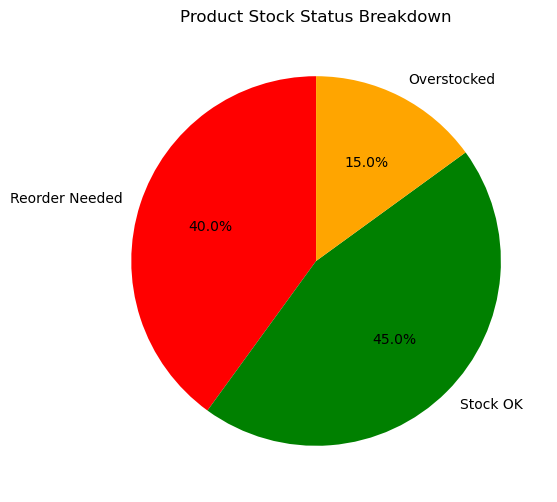

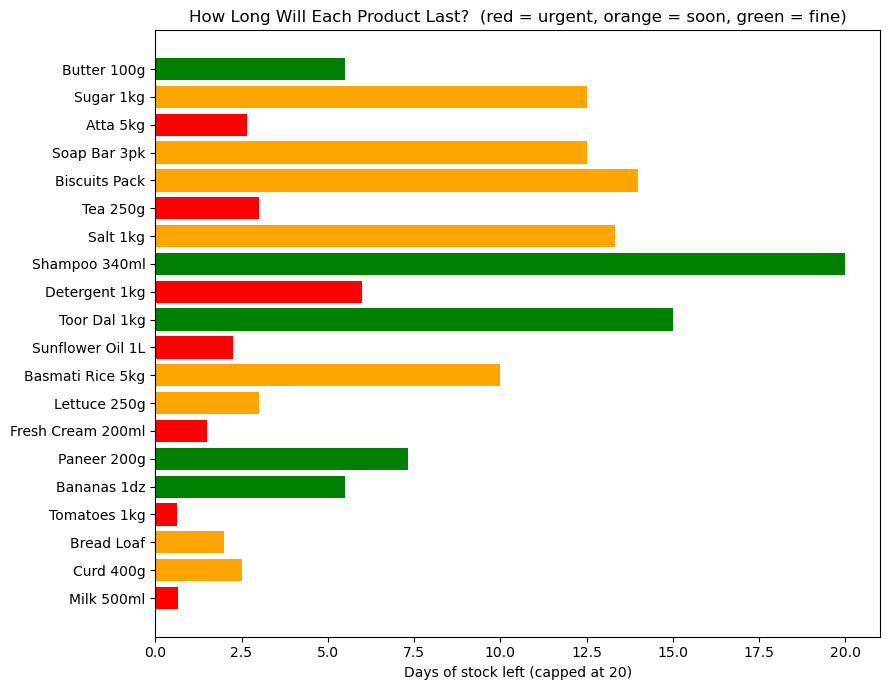

Charts saved as chart_stock_status.png and chart_days_of_cover.png



Press Enter to return to the menu... 



                            DMART STORE MANAGER                             
  1. Inventory status report
  2. Low-stock & overstock alerts
  3. Restock planner
  4. Billing counter
  5. Add a new product
  6. Profit & margin analysis
  7. Sales summary
  8. Charts
  0. Exit
----------------------------------------------------------------------------


Choose an option (0-8):  4



                              BILLING COUNTER                               
Type each item as  CODE,QUANTITY   (example: P-MILK01,3)
Type DONE when the customer has finished.



In [ ]:
main()